# 03 · An agent builds a world

A Strands agent gets two tools, `sim.tool` and `robot.tool`, and edits a MuJoCo world from plain English.
Every turn below is a real Claude call on Amazon Bedrock; the renders and tool calls are what that run did, and a
re-run gets different replies.

![a sentence becomes tool calls, the world rebuilds, the agent looks](media/03/turn.svg)

Needs `uv pip install -e ".[mujoco]" strands-agents` and Bedrock access: `AWS_BEARER_TOKEN_BEDROCK` (or AWS
credentials) plus a model id in `STRANDS_MODEL_ID`.

In [1]:
import io
import json
import os
import sys

import numpy as np
from PIL import Image
from strands import Agent
from strands.tools.executors import SequentialToolExecutor

import _nb
from strands_robots import Robot, Simulation

MEDIA = _nb.MEDIA / "03"
MEDIA.mkdir(parents=True, exist_ok=True)
print("model:", os.environ["STRANDS_MODEL_ID"])

model: global.anthropic.claude-opus-5-5


One world, one SO-101, and a table: a fixed box 4 cm high in front of the arm.


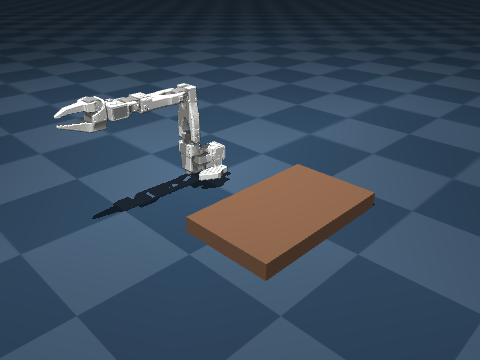

In [2]:
sim = Simulation()
arm = Robot("so101", sim=sim)
sim.add_object("table", shape="box", size=(0.12, 0.2, 0.02), position=(0.3, 0.0, 0.02), color=(0.55, 0.4, 0.3, 1), free=False)
sim.camera("hero", position=(0.85, -0.7, 0.55), target=(0.15, 0.0, 0.05), size=(480, 360))
_nb.show(_nb.image(sim.render("hero"), width=480))

Both tools are generated from the code: one `rpc` selector per tool, one argument object per rpc.

In [3]:
for tool in (sim.tool, arm.tool):
    rpcs = tool.tool_spec["inputSchema"]["json"]["properties"]["rpc"]["enum"]
    print(f"{tool.tool_name:12s} {rpcs}")
print(json.dumps(sim.tool.tool_spec["inputSchema"]["json"]["properties"]["add_object"]["properties"]["shape"]))

sim_world    ['add_robot', 'add_object', 'camera', 'contacts', 'control_step', 'describe', 'pose', 'randomize', 'remove', 'render', 'reset', 'run', 'set_pose', 'step']
robot_so101  ['describe', 'observe', 'act', 'run', 'stop', 'hold', 'estop']
{"type": ["string", "null"], "enum": ["box", "sphere", "cylinder", "capsule", null]}


The agent. `SequentialToolExecutor` runs one tool call at a time: with strands' default (concurrent) executor, a
turn that adds a camera and renders it in the same message can render first and fail.

In [4]:
agent = Agent(
    model=os.environ["STRANDS_MODEL_ID"],
    tools=[sim.tool, arm.tool],
    tool_executor=SequentialToolExecutor(),
    callback_handler=None,
)


SEEN = set()  # tool-call ids already printed (strands trims old messages, so an index into agent.messages drifts)


def new_calls():
    """The tool calls not printed yet, one line each: rpc, its arguments, ok or the error the model read."""
    results = {
        b["toolResult"]["toolUseId"]: b["toolResult"]
        for m in agent.messages for b in m["content"] if "toolResult" in b
    }
    for m in agent.messages:
        for b in m["content"]:
            if "toolUse" in b and b["toolUse"]["toolUseId"] not in SEEN:
                use = b["toolUse"]
                SEEN.add(use["toolUseId"])
                rpc = use["input"].get("rpc")
                res = results.get(use["toolUseId"], {})
                note = "ok" if res.get("status") == "success" else res.get("content", [{}])[0].get("text", "")[:120]
                print(f"  {use['name']}.{rpc}({json.dumps(use['input'].get(rpc) or {})})  -> {note}")


def turn(ask, name):
    """One request: render before, the agent's turn, the calls it made, render after (saved to media/03)."""
    before = sim.render("hero")
    reply = agent(ask)
    after = sim.render("hero")
    print(f"> {ask}\n")
    new_calls()
    print(f"\n{str(reply).strip()}")
    pair = np.concatenate([before, np.full((before.shape[0], 8, 3), 255, np.uint8), after], axis=1)
    Image.fromarray(pair).save(MEDIA / f"{name}.png")
    _nb.show(_nb.image(pair, width=720))

## Turn 1: a red cube on the table

Before on the left, after on the right (the fixed `hero` camera).

> add a red cube on the table

  sim_world.describe({})  -> ok
  sim_world.add_object({"name": "red_cube", "shape": "box", "size": [0.02, 0.02, 0.02], "position": [0.3, 0.0, 0.1], "color": [1, 0, 0, 1], "mass": 0.05})  -> ok
  sim_world.step({"n": 500})  -> ok
  sim_world.pose({"body": "red_cube"})  -> ok
  sim_world.render({"camera": "hero"})  -> ok

I added a red cube to the middle of the table, and the render shows it sitting there.

- **Position:** (0.30, 0.00, 0.06) m, the table's centre, about 30 cm in front of the robot base.
- **Size and mass:** about 4 cm on each side, 50 g.
- **Placement:** I dropped it from a bit above the table and let the physics settle. It came to rest on the tabletop without moving or tipping.

It's called `red_cube` in the scene. I can move it, resize it, or have the SO101 arm try to pick it up.



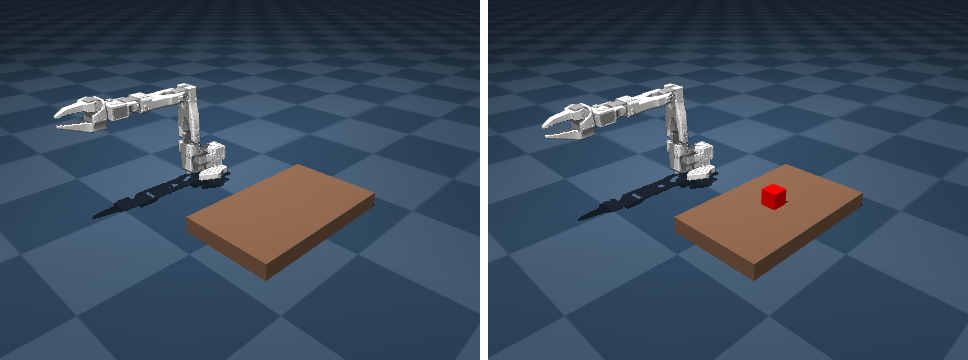

In [5]:
turn("add a red cube on the table", "t1_red_cube")

`size` is MuJoCo's half-extent (a radius for a sphere), and nothing in the tool schema says so: read the cube's `size`
in the call above against the size the reply claims.

## Turn 2: a blue ball and a light

There is no verb that adds a light (`randomize(lighting=)` only scales the existing one), so watch what the agent
says about that half of the request.

> add a blue ball and a light

  sim_world.add_object({"color": [0, 0.3, 1, 1], "mass": 0.03, "name": "blue_ball", "position": [0.35, 0.1, 0.1], "shape": "sphere", "size": 0.02})  -> ok
  sim_world.step({"n": 500})  -> ok
  sim_world.pose({"body": "blue_ball"})  -> ok
  sim_world.randomize({"lighting": 1.5})  -> ok
  sim_world.render({"camera": "hero"})  -> ok

I added the blue ball, but I couldn't add a new light. I made the existing lighting brighter instead.

- **Blue ball:** 4 cm across, 30 g, at (0.35, 0.10, 0.06) m. That's on the table, about 11 cm from the red cube toward the far corner. It settled on the tabletop and isn't rolling.
- **Light:** this sim has no way to add a new light source, such as a lamp at a chosen position or a spotlight. The only lighting control scales the brightness of the lights already in the scene. I set it to 1.5×, and the new render looks noticeably brighter, with the table and objects better lit.

That brightness control can also pick a random brigh


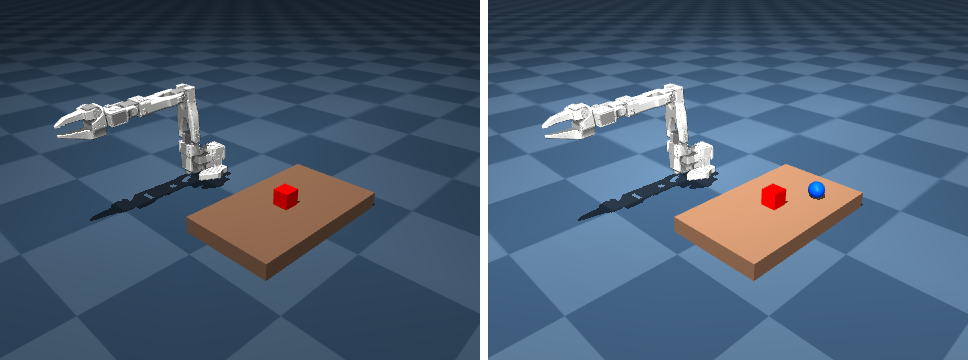

In [6]:
turn("add a blue ball and a light", "t2_ball_and_light")

## Turn 3: a camera looking at the arm

> put a camera looking at the arm

  sim_world.camera({"name": "arm_cam", "position": [0.45, -0.45, 0.4], "target": [0, 0, 0.15], "fov": 60})  -> ok
  sim_world.render({"camera": "arm_cam"})  -> ok
  sim_world.remove({"robot": "arm_cam"})  -> ok
  sim_world.camera({"fov": 60, "name": "arm_cam", "position": [0.25, -0.6, 0.4], "target": [-0.15, 0, 0.18]})  -> ok
  sim_world.render({"camera": "arm_cam"})  -> ok

I added a camera called `arm_cam` that's pointed at the arm. In the last render the whole arm is centred in the frame, from base to gripper.

- **Position:** (0.25, −0.60, 0.40) m, in front of the arm, off to the side and a little above it.
- **Aimed at:** (−0.15, 0, 0.18) m, roughly the middle of the arm in its current pose.
- **Field of view and resolution:** 60°, 640×480.

My first try put the arm off to the left with the table filling much of the frame, so I moved and re-aimed it. Now the table shows only at the bottom-right edge, with the red cube visible and the blue ball ju


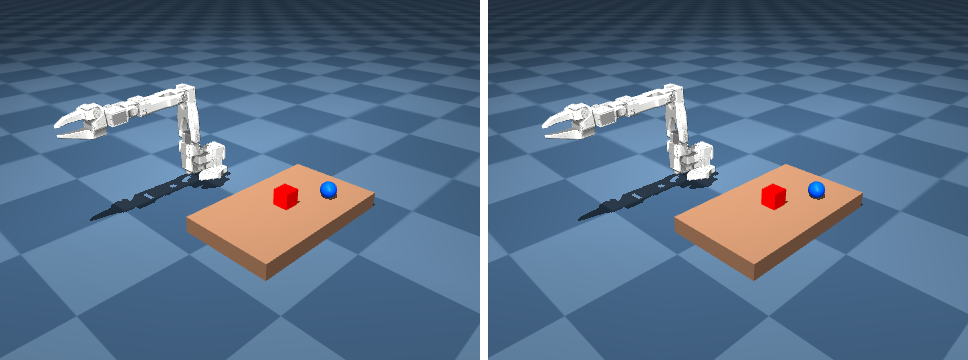

In [7]:
turn("put a camera looking at the arm", "t3_camera")

## Turn 4: the agent looks through its camera

`render` returns the picture as an image block, so the model sees it. Below is the exact image it was sent.

  sim_world.render({"camera": "arm_cam"})  -> ok

The white SO101 arm is centred in the frame, standing upright with its gripper open and reaching left, away from the table, while the tan table with the red cube and the edge of the blue ball sits in the bottom-right corner.



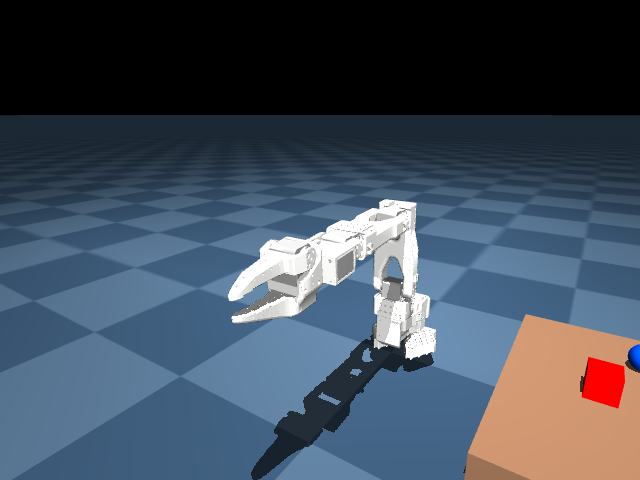

In [8]:
reply = agent("render the camera you added and tell me in one sentence what you see")
new_calls()
print(f"\n{str(reply).strip()}")
seen = [
    c["image"]["source"]["bytes"]
    for m in agent.messages for b in m["content"] if "toolResult" in b
    for c in b["toolResult"]["content"] if "image" in c
]
saw = np.asarray(Image.open(io.BytesIO(seen[-1])).convert("RGB"))
Image.fromarray(saw).save(MEDIA / "t4_what_the_agent_saw.png")
_nb.show(_nb.image(saw, width=480))

## The world it built

`describe()` is what the agent reads too.

In [9]:
world = sim.describe()
for o in world["objects"]:
    print(f"{o['name']:10s} {o['shape']:8s} at {np.round(o['position'], 3).tolist()}")
print("cameras:", [c["name"] for c in world["cameras"]])

table      box      at [0.3, 0.0, 0.02]
red_cube   box      at [0.3, -0.0, 0.06]
blue_ball  sphere   at [0.35, 0.1, 0.06]
cameras: ['hero', 'arm_cam']


An orbit around it. There is no verb that moves a camera, so each frame is `remove` + `camera` again, a rebuild.

In [10]:
frames = []
for i in range(36):
    a = 2 * np.pi * i / 36
    if i:
        sim.remove("orbit")
    sim.camera("orbit", position=(0.15 + 0.75 * np.cos(a), 0.75 * np.sin(a), 0.5), target=(0.15, 0.0, 0.05), size=(400, 300))
    frames.append(sim.render("orbit"))
_nb.gif(frames, "03/orbit.gif", width=400, fps=12)

media/03/orbit.gif: 36 frames, 1.31 MB


PosixPath('/Users/cagatay/robots-test-cagatay/notebooks/media/03/orbit.gif')

![orbit of the world the agent built](media/03/orbit.gif)

## Your turn

The same agent in a loop. In a terminal: `python notebooks/scripts/03_agent_builds_a_world.py --repl`.

In [11]:
if "--repl" in sys.argv:
    while True:
        print(agent(input("> ")))

In [12]:
sim.close()